In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-


# Deep Neural Networks

## Session 03 - Activation Functions


<img src='../../prasami_images/prasami_color_tutorials_small.png' width='400' alt="By Pramod Sharma : pramod.sharma@prasami.com" align="left"/>

In [ ]:
# Lets import some libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import (MultipleLocator, 
                               FormatStrFormatter,
                               AutoMinorLocator)

In [3]:
# Some basic parameters
inpDir = '../input'
outDir = '../output'

RANDOM_STATE = 24

np.random.seed(RANDOM_STATE) # Set Random Seed for reproducible  results

# parameters for Matplotlib
params = {'legend.fontsize': 'large',
          'figure.figsize': (15, 6),
          'axes.labelsize': 'large',
          'axes.titlesize':'large',
          'xtick.labelsize':'medium',
          'ytick.labelsize':'medium'
         }

CMAP = plt.cm.Blues

plt.rcParams.update(params)

## Fabricate Data

In [4]:
# create x data points
x_min = -5
x_max = 5
step = 0.01
x_range = np.arange(x_min, x_max, step) # create an array in the rage

In [5]:
data_df = pd.DataFrame(x_range, columns = ['x'], dtype = np.float64)#.round(4)
data_df.head()

,x
0,-5.00
1,-4.99
2,-4.98
3,-4.97
4,-4.96


## Helper Functions

In [6]:
# Function for plotting

def fn_plot_activation(axes, df, c1, c2, yMajLoc = 1, yMinLoc = 0.2):
    
    '''
    Args:
        axes : need two axes to plot function and its prime
        df : dataframe having values
        c1, c2: str column names to plot
        yMajLoc = 1, yMinLoc = 0.2 : Major and minor ticks spacing on y axis
    
    '''
    

    # for plotting of function
    ax = axes[0]
    
    # plot column 1 (function it self) 
    df.plot(x = 'x', y = c1, ax = ax, c = 'b', rot = 90, lw=3)
    
    ax.set_xlabel ('Input')
    
    # horizontal lines for axis marking
    ax.axhline(0, c = 'k', lw = 2)
    ax.axvline(0, c = 'k', lw=2)

    # show only major grid
    ax.grid(which='major', axis='both')
    
    # set major axis and format display of labels
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%3.1f'))

    # For the minor ticks, use no labels; default NullFormatter
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))

    # set major axis and format display of labels
    ax.yaxis.set_major_locator(MultipleLocator(yMajLoc))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%3.1f'))

    # For the minor ticks, use no labels; default NullFormatter.
    ax.yaxis.set_minor_locator(MultipleLocator(yMinLoc))
    
    # Now using second axis for plotting derivative
    ax = axes[1]
    df.plot(x = 'x', y = c2, ax = ax, c = 'b', rot = 90, lw=3)
    
    ax.set_xlabel ('Input')
    
    # horizontal lines for axis marking
    ax.axhline(0, c = 'k', lw = 2)
    ax.axvline(0, c = 'k', lw = 2)

    # show only major grid
    ax.grid(which='major', axis='both')
    
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%3.1f'))

    # For the minor ticks, use no labels; default NullFormatter.
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))

    ax.yaxis.set_major_locator(MultipleLocator(yMajLoc))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%3.1f'))

    # For the minor ticks, use no labels; default NullFormatter.
    ax.yaxis.set_minor_locator(MultipleLocator(yMinLoc))
    

# Function to mark equation on the image
def fn_plot_equation(ax, x , y, text):
    '''
        ax : axis 
        x  : Horizontal position
        y  : Vertical position
        text : text to plot
    '''
    
    ax.text(x, y, text, {'color': 'k',
                         'fontsize': 'x-large',
                         'verticalalignment' : 'top',
                         'horizontalalignment' : 'left',
                         #'fontweight' :'bold',
                         'style' : 'italic'},
            
            bbox={'facecolor': 'cyan',
                  'alpha': 0.3,
                  'pad': 5 })

## Linear Function

Linear function is some multiple of the values

In [7]:
def linear (z,m ) :
    '''
        z : values coming from aggregator
        m: multiplier
    '''
    return m*z

# Derivative of the function
def linear_prime (z,m ) :
    
    return m

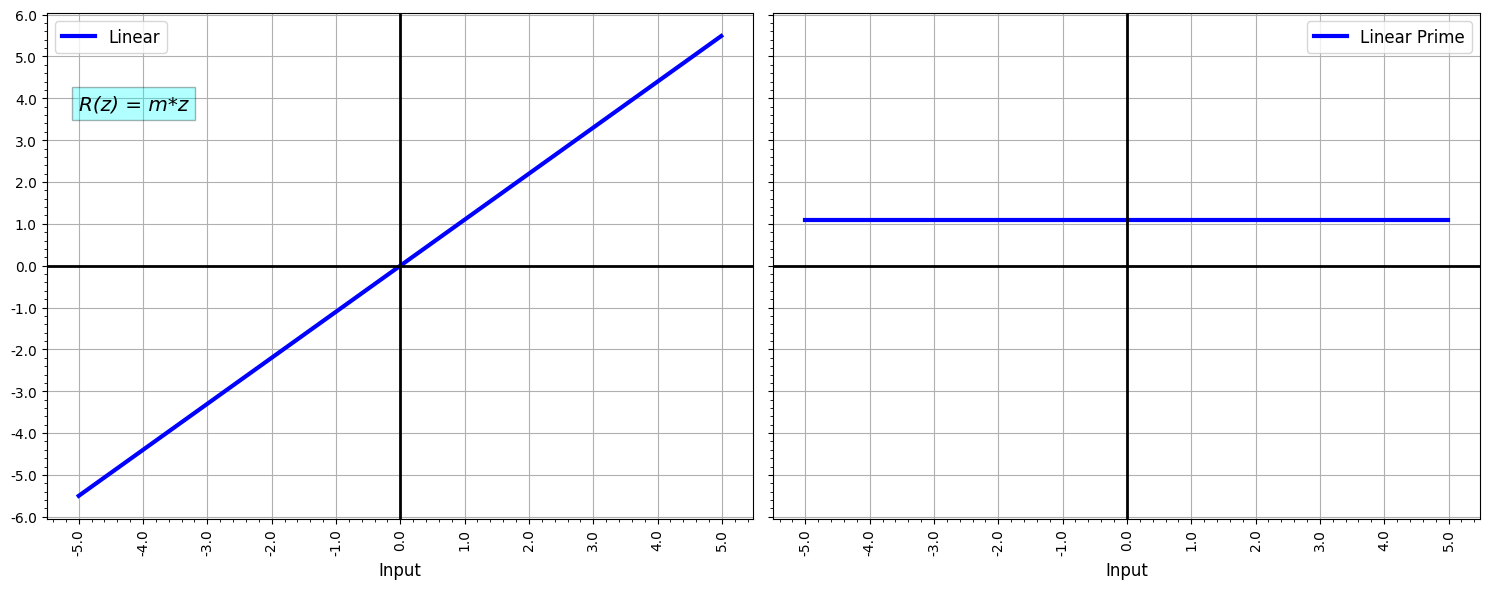

In [8]:
m = 1.1

# select columns to plot
col1 = 'Linear'
col2 = 'Linear Prime'

# add two columns in the dataframe for function values and its prime
data_df[col1] = data_df['x'].apply(lambda x: linear (x,m ))
data_df[col2] = data_df['x'].apply(lambda x: linear_prime (x,m ))

# create figure and its axis objects
fig, axes = plt.subplots(1, 2, sharey=True)



# calling function to plot the columns
fn_plot_activation(axes, data_df, col1, col2)

# mark text on axis 
ax =axes[0]
eq = r'R(z) = m*z'

xLoc = -5
yLoc = 4.1

fn_plot_equation(ax, xLoc , yLoc, eq)

plt.tight_layout()

# save figures to update the presentations
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Sigmoid

The sigmoid function, also called the sigmoidal curve (von Seggern 2007, p. 148) or logistic function, is the s shaped function represented by:

R(z) = $\frac{1}{1 + e^{-z}}$

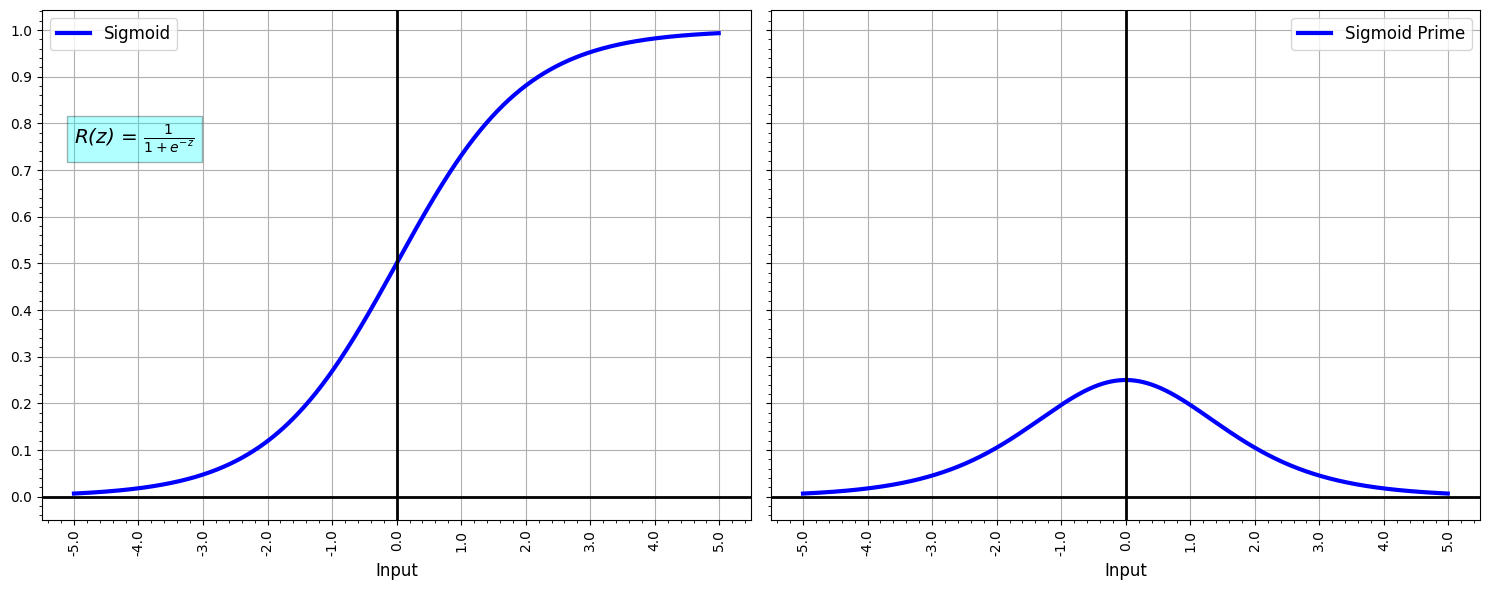

In [9]:
def sigmoid(z):
    return 1.0 / (1 + np.exp(-z))

def sigmoid_prime(z):
    return sigmoid(z) * ( 1 - sigmoid(z))


col1 = 'Sigmoid'
col2 = 'Sigmoid Prime'

# add two columns in the dataframe for function values and its prime
data_df[col1] = data_df['x'].apply(lambda x: sigmoid (x))
data_df[col2] = data_df['x'].apply(lambda x: sigmoid_prime (x))

# create figure and its axis objects
fig, axes = plt.subplots(1, 2, sharey=True)

# Select Major and Minor axis formatings
yMajorLocator = 0.1
yMinorLocator = 0.02
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

# Define the equation
eq1 = r'R(z) = $\frac{1}{1 + e^{-z}}$'

ax = axes[0]
xLoc = -5
yLoc = 0.8

fn_plot_equation(ax, xLoc , yLoc, eq1)
plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Tanh

$\tanh(z) =\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$

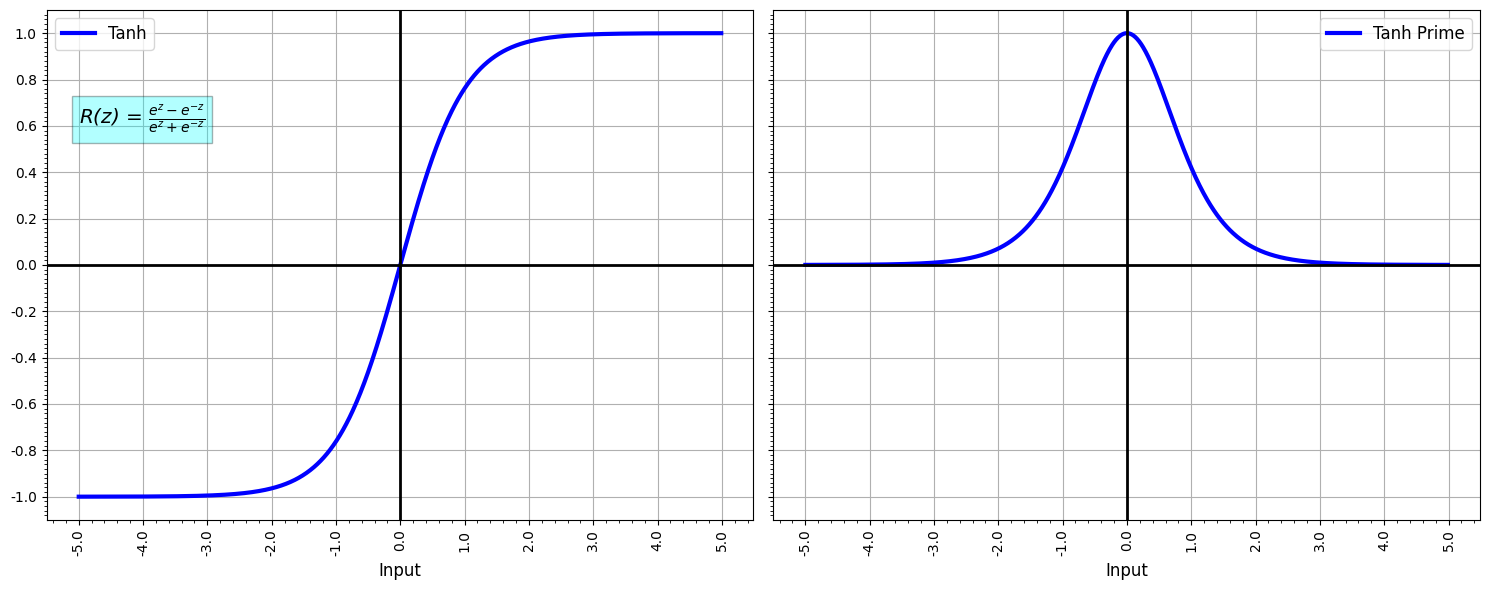

In [10]:
def tanh(z):
    return (np.exp(z) - np.exp(-z)) / (np.exp(z) + np.exp(-z))

def tanh_prime(z):
    return 1 - np.power(tanh(z), 2)

col1 = 'Tanh'
col2 = 'Tanh Prime'

data_df[col1] = data_df['x'].apply(lambda x: tanh (x))
data_df[col2] = data_df['x'].apply(lambda x: tanh_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)


yMajorLocator = 0.2
yMinorLocator = 0.02
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)


ax = axes[0]
eq1 = r'R(z) = $\frac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$'

xLoc = -5
yLoc = 0.7
fn_plot_equation(ax, xLoc , yLoc, eq1)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Inverse tangent function
$
\begin{align}
f(z) &= tan^{-1}(z)\\
f'(z)&= \dfrac{1}{1+z^2}
\end{align}
$

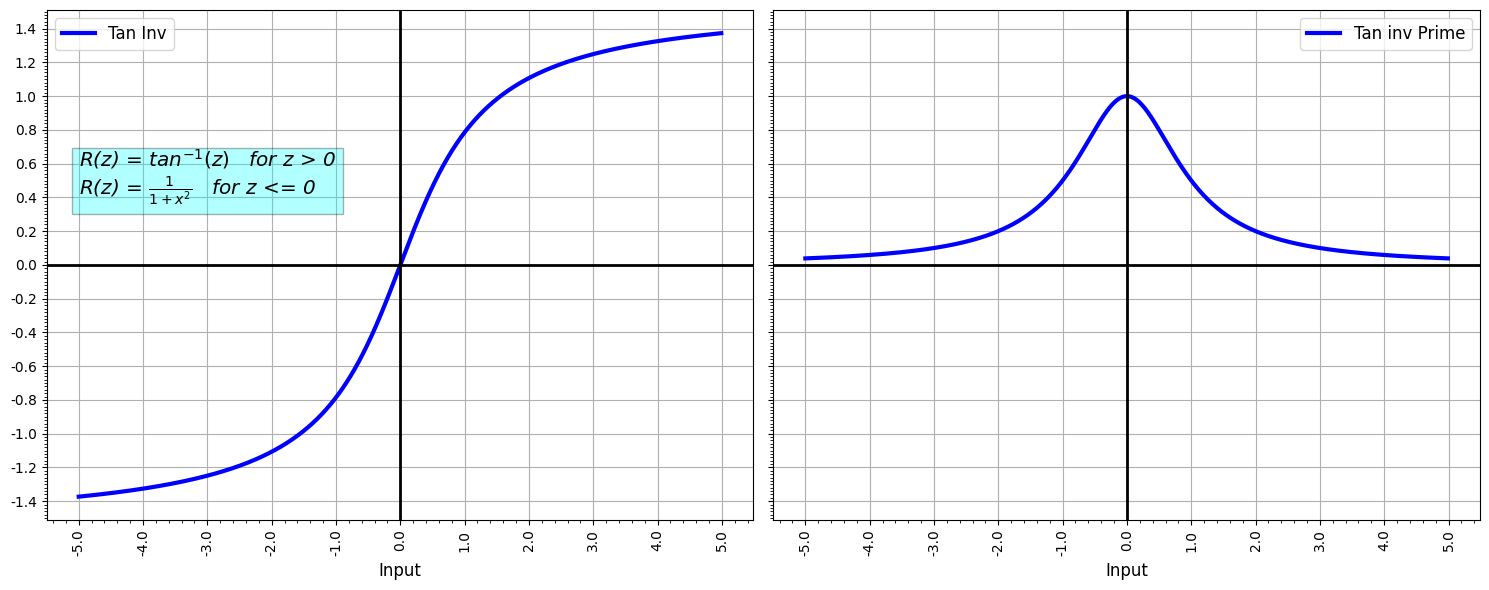

In [11]:
def activ(z):
    return np.arctan(z)

def actv_prime(z):
    return 1/ (1 + np.power(z, 2))

col1 = 'Tan Inv'
col2 = 'Tan inv Prime'

data_df[col1] = data_df['x'].apply(lambda x: activ (x))
data_df[col2] = data_df['x'].apply(lambda x: actv_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)


yMajorLocator = 0.2
yMinorLocator = 0.02
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)


ax = axes[0]
eq1 = r'R(z) = $tan^{-1}(z)$   for z > 0'
eq2 = r'R(z) = $\frac{1}{1+x^2}$   for z <= 0'

eq = '{}\n{}'.format(eq1,eq2)

xLoc = -5
yLoc = 0.7
fn_plot_equation(ax, xLoc , yLoc, eq)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Rectified Linear Units (ReLU)
$
\begin{align}
ReLU(z) = \left\{
\begin{array}{cl}
z & \text{for z} \gt 0\\
0  & \text{for z} \le 0.
\end{array}
\right.
\end{align}
$

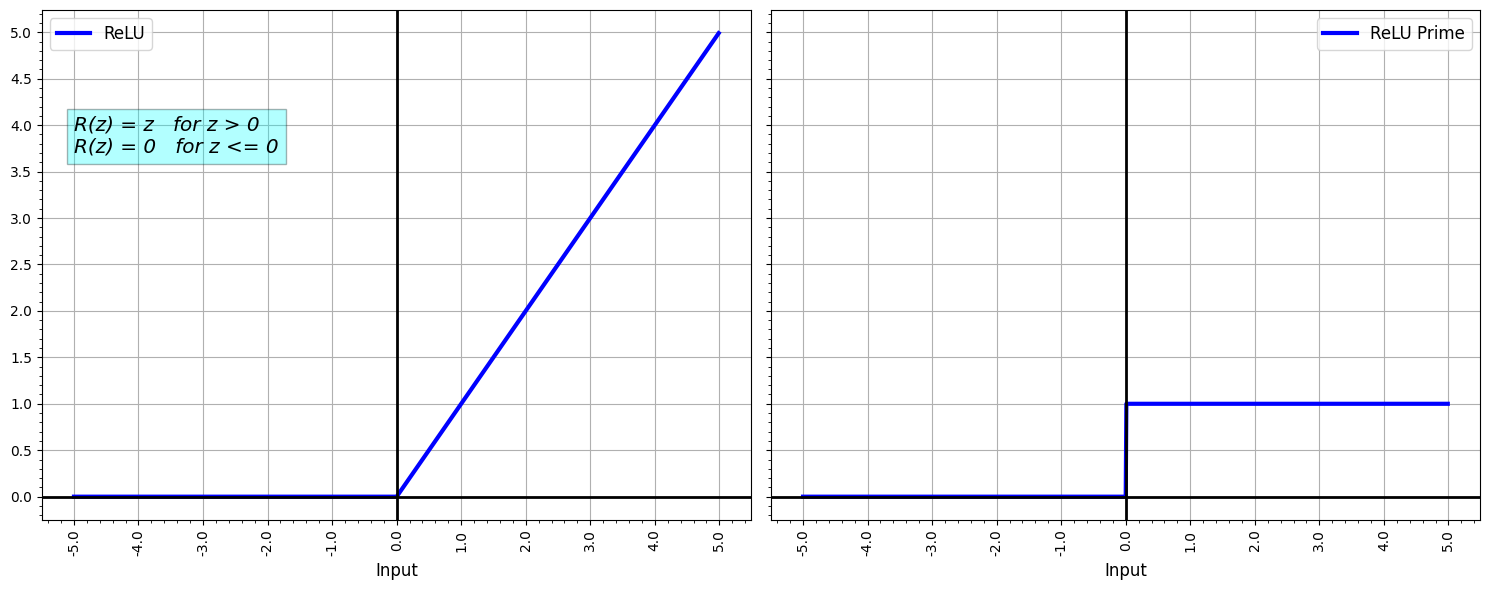

In [12]:
def relu(z):
    return max(0, z)

def relu_prime(z):
    return 1 if z > 0 else 0

col1 = 'ReLU'
col2 = 'ReLU Prime'

data_df[col1] = data_df['x'].apply(lambda x: relu (x))
data_df[col2] = data_df['x'].apply(lambda x: relu_prime (x ))

fig, axes = plt.subplots(1, 2, sharey=True)



yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'R(z) = z   for z > 0'
eq2 = r'R(z) = 0   for z <= 0'

eq = '{}\n{}'.format(eq1,eq2)


xLoc = -5
yLoc = 4.1

fn_plot_equation(ax, xLoc , yLoc, eq)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## LeakyReLU

$
\begin{align}
\text{LeakyReLU(z)} = \left\{
\begin{array}{cl}
z & \text{for z} \gt 0\\
\alpha \times z & \text{for z} \le 0.
\end{array}
\right.
\end{align}
$

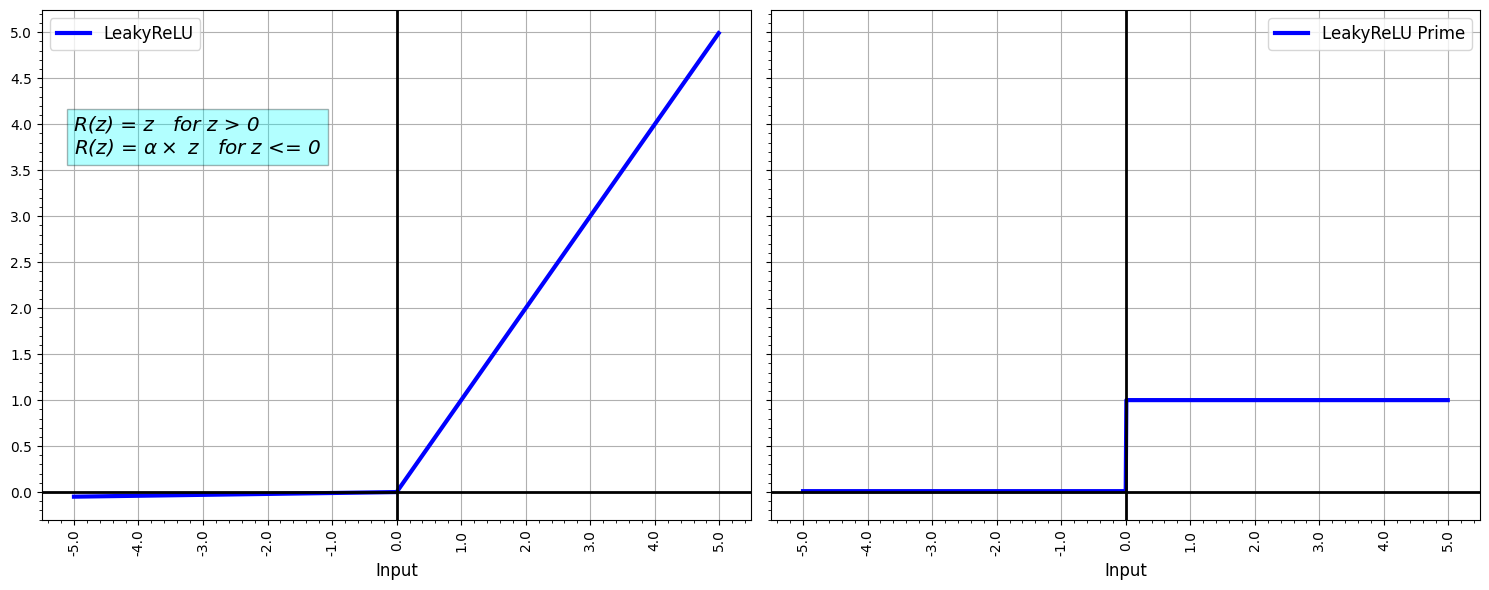

In [13]:
def leakyrelu(z, alpha):
    return max(alpha * z, z)

def leakyrelu_prime(z, alpha):
    return 1 if z > 0 else alpha

col1 = 'LeakyReLU'
col2 = 'LeakyReLU Prime'

alpha = 0.01 # 

data_df[col1] = data_df['x'].apply(lambda x: leakyrelu (x,alpha ))
data_df[col2] = data_df['x'].apply(lambda x: leakyrelu_prime (x,alpha ))

fig, axes = plt.subplots(1, 2, sharey=True)



yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)


eq1 = r'R(z) = z   for z > 0'
eq2 = r'R(z) = $\alpha \times$ z   for z <= 0'

eq = '{}\n{}'.format(eq1,eq2)

ax = axes[0]
xLoc = -5
yLoc = 4.1
fn_plot_equation(ax, xLoc , yLoc, eq)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Exponential Linear Unit (ELU)
$
\begin{align}
ELU(z) = \left\{
\begin{array}{cl}
z & \text{for z} \gt 0\\
\alpha \times (e^{z} - 1)  & \text{for z} \le 0.
\end{array}
\right.
\end{align}
$

WHEN TO USE:
- When you need to avoid dying ReLU problem
- For faster learning convergence
- When negative values are important for representation
- Good for classification tasks

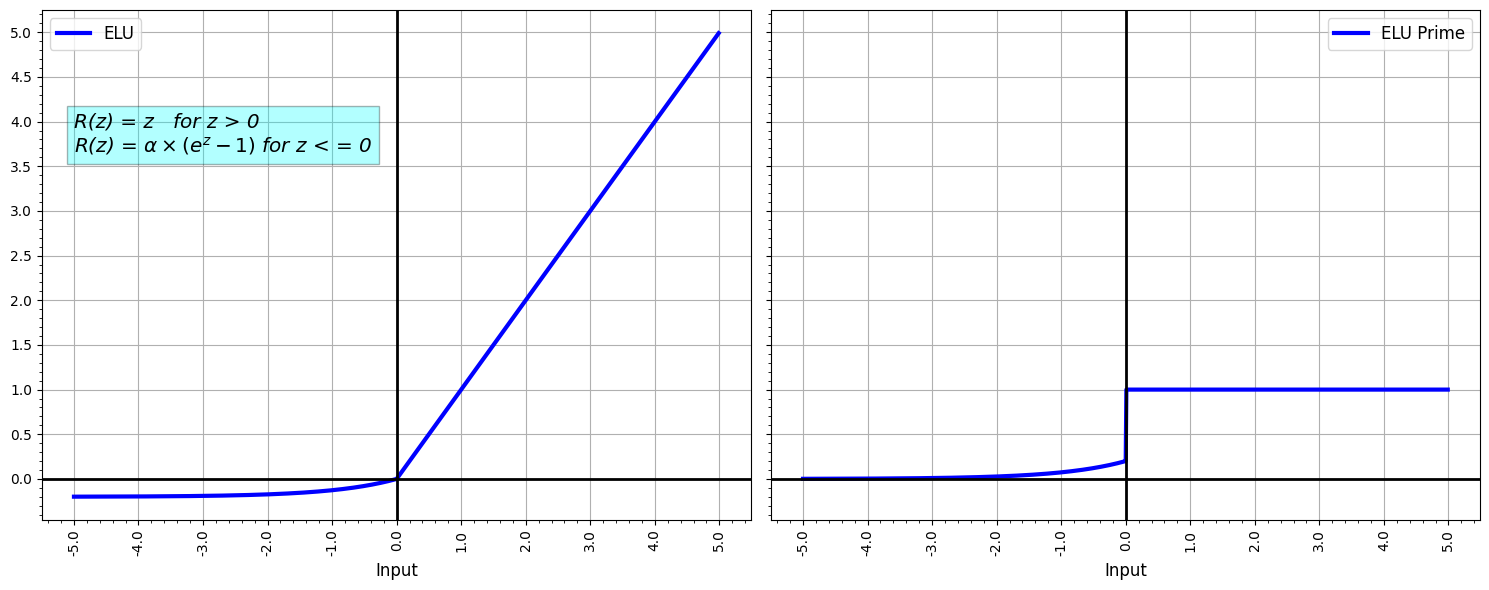

In [14]:
def elu(z,alpha):
    return z if z >= 0 else alpha*(np.exp(z) -1)

def elu_prime(z,alpha):
    return 1 if z >= 0 else alpha*np.exp(z)

alpha = 0.2 # a common value is between 0.1 and 0.3.


col1 = 'ELU'
col2 = 'ELU Prime'

data_df[col1] = data_df['x'].apply(lambda x: elu (x,alpha ))
data_df[col2] = data_df['x'].apply(lambda x: elu_prime (x,alpha ))

fig, axes = plt.subplots(1, 2, sharey=True)


yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)
ax =axes[0]

eq1 = r'R(z) = z   for z > 0'
eq2 = r'R(z) = $\alpha \times (e^{z} - 1)$ for z < = 0'

eq = '{}\n{}'.format(eq1,eq2)

xLoc = -5
yLoc = 4.1

fn_plot_equation(ax, xLoc , yLoc, eq)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Scaled ELU (SELU)
SELU units, when used in conjunction with proper weight initialization and regularization techniques, encourage neuron activations to converge to zero-mean and unit variance without explicit use of e.g., batchnorm. For SELU units, the $\alpha$ and $\text{scale}$ values are constants chosen so that the mean and variance of the inputs are preserved between consecutive layers. As such the authors propose weights be initialized using Lecun-Normal initialization: 

$w_{ij} \sim  \mathcal{N}(0, \frac{1} {fan_in})$
,
    
and to use the dropout variant $\alpha$-dropout during regularization.  

**See the reference for more information (especially the appendix )**.
    
### References
    .. [*] Klambauer, G., Unterthiner, T., & Hochreiter, S. (2017).
       "Self-normalizing neural networks." *Advances in Neural Information
       Processing Systems, 30.*
       
       
Evaluate the SELU activation on the elements of input `z`.
        
$
\begin{aligned}
\text{SELU}(z)  &=  \text{scale}  \text{ELU}(z, \alpha)\\
\end{aligned}
$

Which is simply

$
\begin{aligned}
\text{SELU}(z)  = \left\{
\begin{array}{cl}
\text{scale} \times z & \text{for z} \ge 0\\
\text{scale} \times \alpha \times (e^{z} - 1)  & \text{for z} \lt 0.
\end{array}
\right.
\end{aligned}
$


The first derivative of the SELU activation on the elements of input `z`.

$
\begin{aligned}
\frac{\partial \text{SELU}}{\partial z_i} = \left\{
\begin{array}{cl}
\text{scale} \ \ \ \ &&& \text{for z} \ge 0\\
\text{scale} \times \alpha \times e^{z_i} \ \ \ \ &&&\text{for z} \lt 0.
\end{array}
\right.
\end{aligned}
$

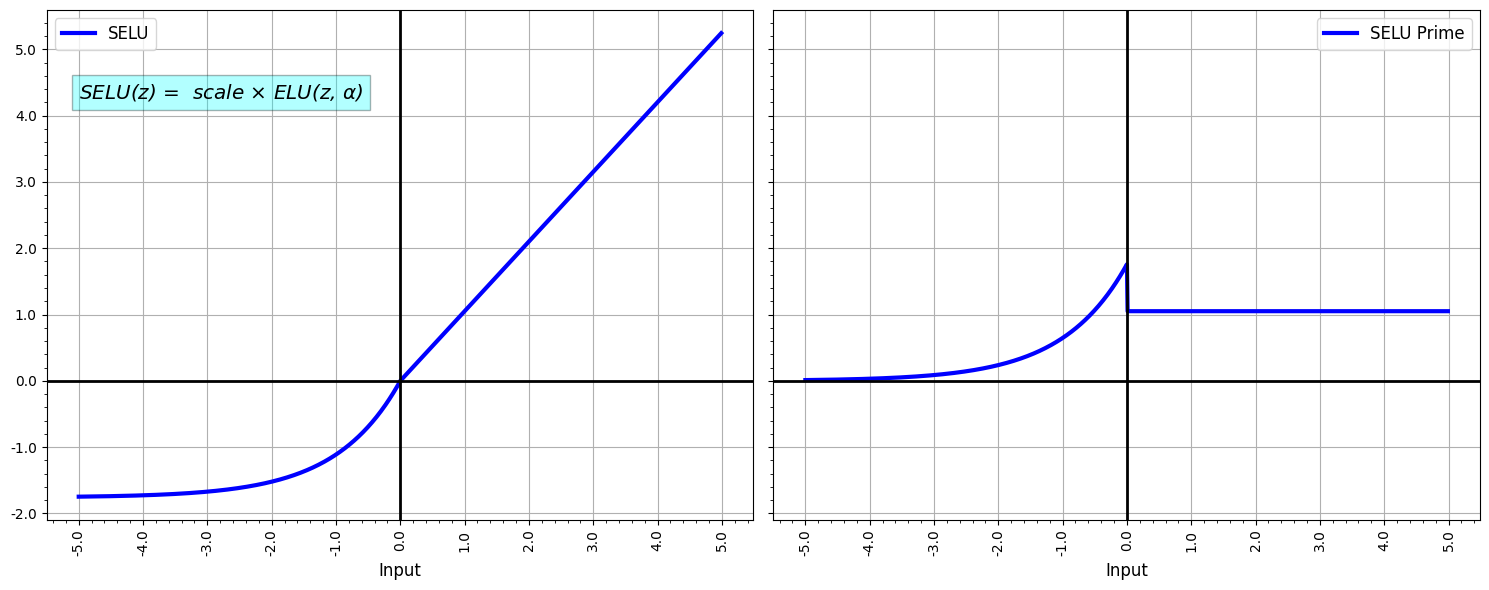

In [15]:
# Alpha and scales as per tensorflow documentations
alpha=1.67326324 
scale=1.05070098

def fn_elu(z, alpha = alpha):
    return z if z >= 0 else alpha*(np.exp(z) -1)

def fn_elu_prime(z,alpha):
    return 1 if z > 0 else alpha*np.exp(z)


def selu(z, scale = scale):

    return scale * fn_elu(z)

def selu_prime(x, scale = scale, alpha = alpha):
    return np.where(x >= 0, 
                    np.ones_like(x) * scale, 
                    np.exp(x) * alpha * scale)

col1 = 'SELU'
col2 = 'SELU Prime'

data_df[col1] = data_df['x'].apply(lambda x: selu (x))
data_df[col2] = data_df['x'].apply(lambda x: selu_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)

fn_plot_activation(axes, data_df, col1, col2)

eq1 = r'SELU(z) =  scale $\times$ ELU(z, $\alpha$)'

ax = axes[0]

xLoc = -5
yLoc = 4.5
fn_plot_equation(ax, xLoc , yLoc, eq1)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Seagull (Simple, Efficient Activation)
$
\begin{align}
seagull(z) = \left\{
\begin{array}{cl}
z & \text{for z} \ge 0\\
\alpha \times z  & \text{for z} \lt 0.
\end{array}
\right.
\end{align}
$

where $\alpha$ is -0.2.

WHEN TO USE:
- When you need ReLU-like simplicity but want to avoid dying neurons
- For fast inference in production systems
- When computational efficiency is critical
- Good drop-in replacement for Leaky ReLU

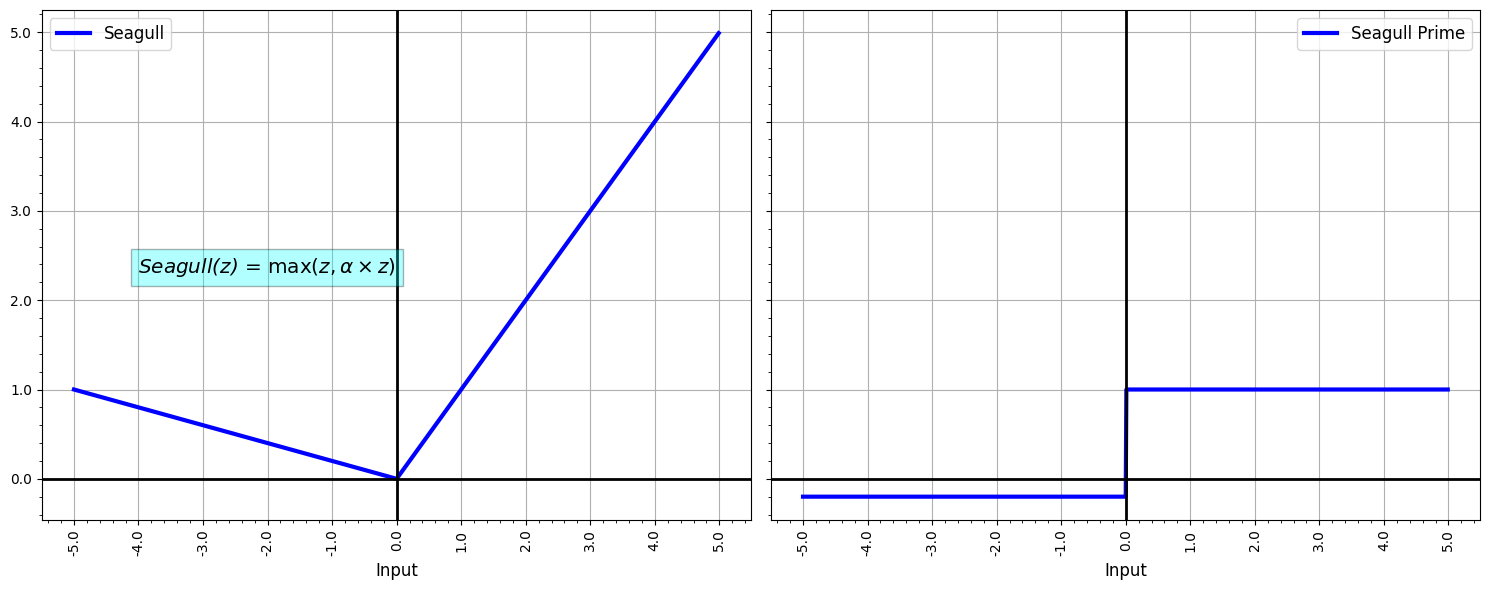

In [16]:
def seagull(z, alpha=-0.2):
    return np.maximum(z, alpha * z)

def seagull_prime(z, alpha=-0.2):
    return np.where(z > 0, 1, alpha)

col1 = 'Seagull'
col2 = 'Seagull Prime'

# add two columns in the dataframe for function values and its prime
data_df[col1] = data_df['x'].apply(lambda x: seagull(x))
data_df[col2] = data_df['x'].apply(lambda x: seagull_prime(x))

# create figure and its axis objects
fig, axes = plt.subplots(1, 2, sharey=True)

# Select Major and Minor axis formatings
yMajorLocator = 1.0
yMinorLocator = 0.2
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

# Define the equation
eq1 = r'Seagull(z) = $\max(z, \alpha \times z)$'

ax = axes[0]
xLoc = -4
yLoc = 2.5

fn_plot_equation(ax, xLoc , yLoc, eq1)
plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Swish Activation Function
*(SiLU (Sigmoid Linear Unit) - Same as Swish)*
The Swish function is defines as 

swish(z) = z * sigmoid(z)

**Note:** we will be using sigmoid function defined above

WHEN TO USE:
- General replacement for ReLU in deep networks
- Often outperforms ReLU in very deep networks (50+ layers)
- Good default choice for CNNs and Transformers
- Provides smooth, non-monotonic behavior

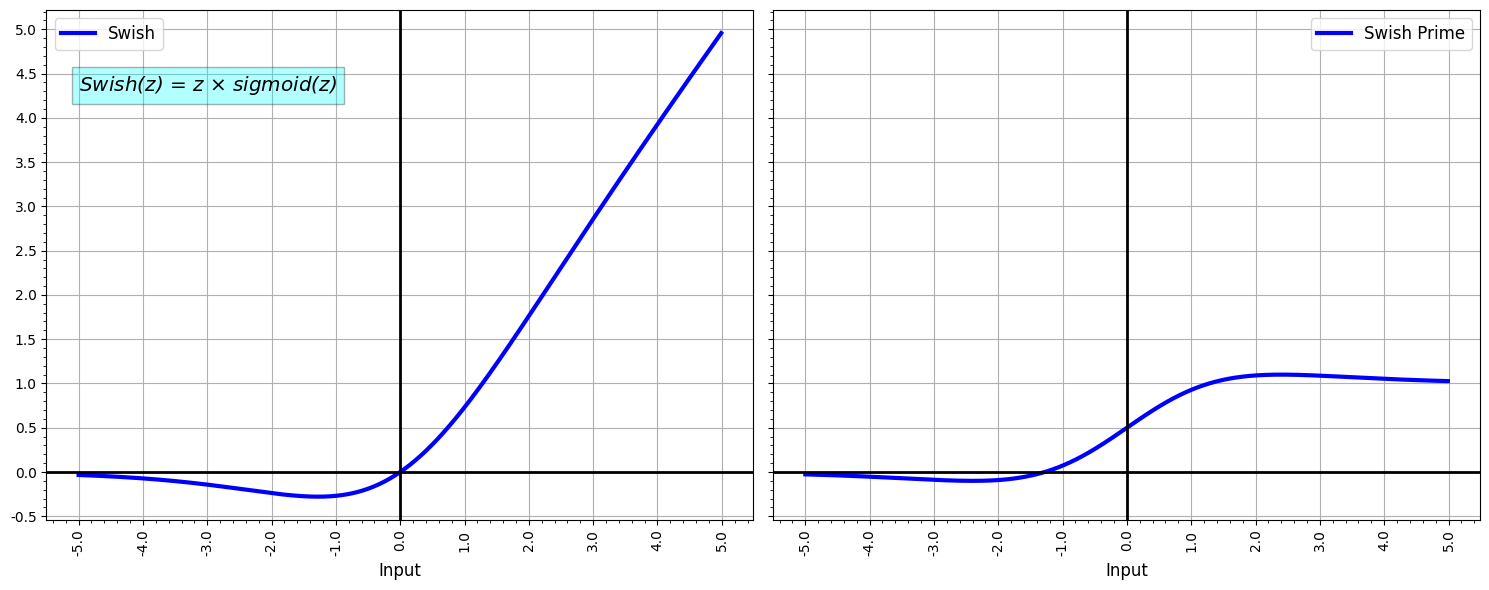

In [17]:
def swish(z):
    return z * sigmoid(z)

def swish_prime(z):
    dz = 1e-6 
    dj = swish ( z + dz ) - swish ( z - dz )
    return dj / (2 * dz)
    # Alternatively return sig + z * sig * (1 - sig)

col1 = 'Swish'
col2 = 'Swish Prime'

data_df[col1] = data_df['x'].apply(lambda x: swish (x))
data_df[col2] = data_df['x'].apply(lambda x: swish_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'Swish(z) = z $\times$ sigmoid(z)'

xLoc = -5
yLoc = 4.5
fn_plot_equation(ax, xLoc , yLoc, eq1)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## LiSHT

The activation function in neural network is one of the important aspects which facilitates the deep training by introducing the non-linearity into the learning process. However, because of zero-hard rectification, some the of existing activations function such as ReLU and Swish miss to utilize the negative input values and may suffer from the dying gradient problem. Thus, it is important to look for a better activation function which is free from such problems. As a remedy, this paper proposes a new non-parametric function, called Linearly Scaled Hyperbolic Tangent (LiSHT) for Neural Networks (NNs). The proposed LiSHT activation function is an attempt to scale the non-linear Hyperbolic Tangent (Tanh) function by a linear function and tackle the dying gradient problem.

$LiSHT(z) = x \times Tanh(z)$

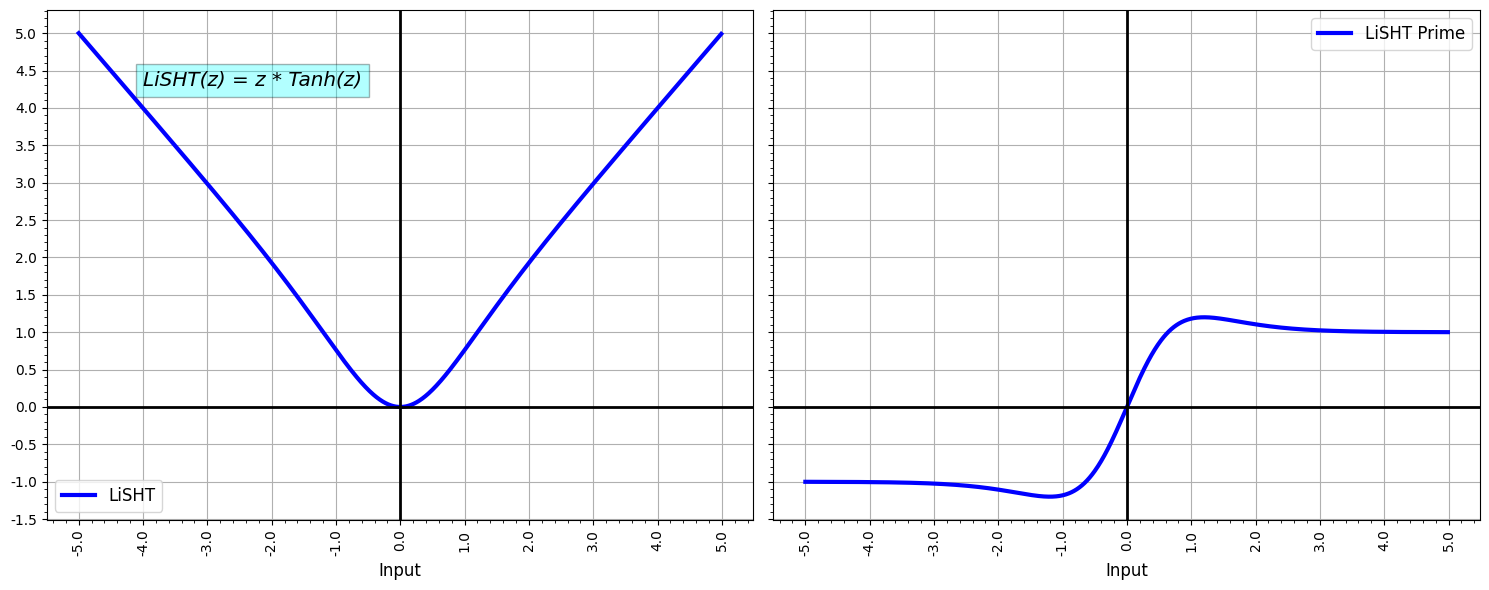

In [18]:
def lisht(z):
    return z * np.tanh(z)


def lisht_prime(z):
    dz = 1e-6 
    dj = lisht ( z + dz ) - lisht ( z - dz )
    return dj / (2 * dz)


col1 = 'LiSHT'
col2 = 'LiSHT Prime'


data_df[col1] = data_df['x'].apply(lambda x: lisht (x))

data_df[col2] = data_df['x'].apply(lambda x: lisht_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)



yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

eq1 = r'LiSHT(z) = z * Tanh(z)'


ax = axes[0]

xLoc = -4.0
yLoc = 4.5
fn_plot_equation(ax, xLoc , yLoc, eq1)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## Mish Activation Function
$
\begin{align}
mish(z) &= x * tanh(softplus(z))\\
& = z * tanh(ln(1 + e^{z}))\\
\end{align}
$

WHEN TO USE:
- Computer vision tasks (often outperforms Swish in CNNs)
- When you need smooth, non-monotonic behavior
- Good for avoiding dying neurons problem
- Often used in state-of-the-art vision models


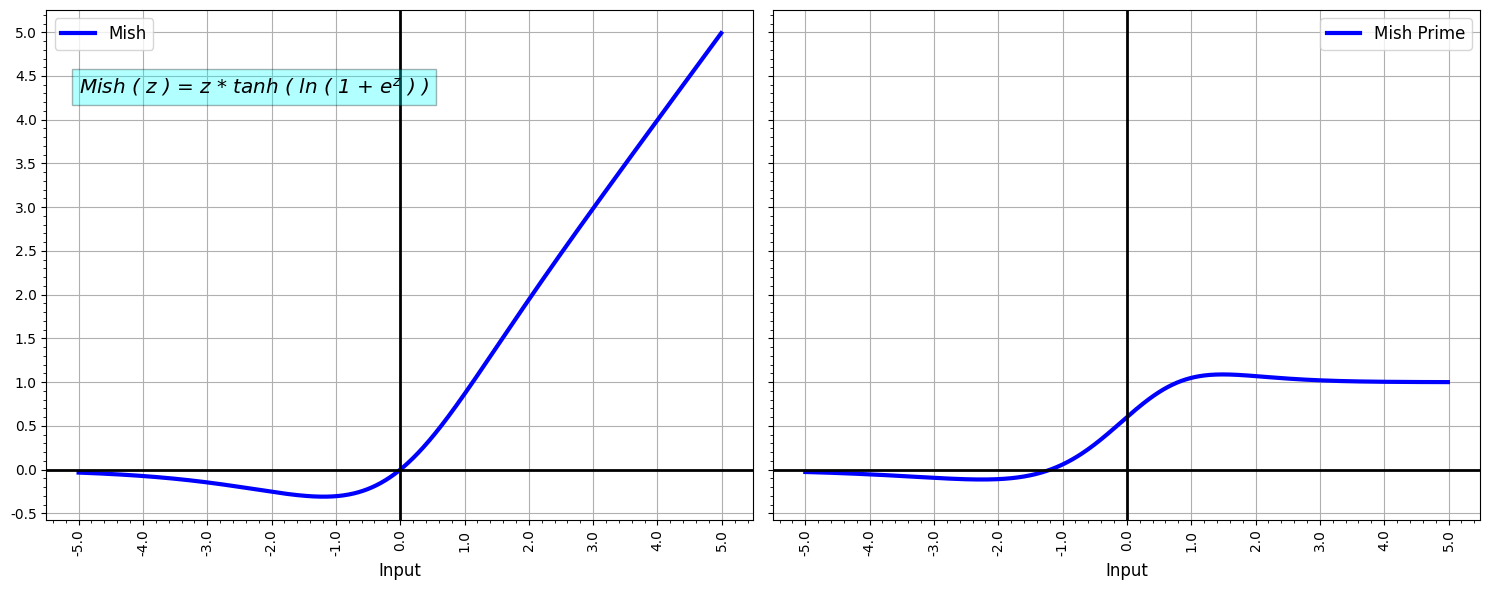

In [19]:
def mish(x):
    return x * np.tanh(np.log(1 + np.exp(x)))


def mish_prime(z):
    dz = 1e-6 
    dj = mish ( z + dz ) - mish ( z - dz )
    return dj / (2 * dz)

col1 = 'Mish'
col2 = 'Mish Prime'

data_df[col1] = data_df['x'].apply(lambda x: mish (x))

data_df[col2] = data_df['x'].apply(lambda x: mish_prime (x))

fig, axes = plt.subplots(1, 2, sharey=True)



yMajorLocator = 0.5
yMinorLocator = 0.1
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

eq1 = r'Mish ( z ) = z * tanh ( ln ( 1 + $e^{z}$ ) )'


ax = axes[0]

xLoc = -5
yLoc = 4.5
fn_plot_equation(ax, xLoc , yLoc, eq1)

plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

## GELU (Gaussian Error Linear Unit) Activation Function
*Making the Team Smarter and More Resilient* Since we have more processing power

The GELU activation function combines properties of dropout, zoneout, and ReLUs.The Big Idea: 
The GELU activation function is defined as:

$
\begin{align}
GELU(z) &= z⋅\Phi(z) \\
&= z\frac{1}{2}[1+erf(\frac{z}{\sqrt{2}})]
\end{align}
$

Approximately:

$GELU(z)≈0.5z\circ(1+tanh[\sqrt{\frac{2}{\pi}}\circ(z+0.044715 z^{3})])$

#### Derivative

The derivative of GELU is:

GELU′(z)=$\Phi$(z)+z $\circ$ $\phi$(z)

Where:

$\Phi(z)$ is the Cumulative Distribution Function ("What Percentage")  of standard normal distribution

$\phi(z)$ is the Probability Density Function ("How Likely") of standard normal distribution: $\phi(z) = \frac{1}{\sqrt{2\pi}}e^{-z^2/2}$

The GELU activation function is designed to mimic kind of smart, probabilistic behavior naturally, without needing to randomly turn things on and off.

### Properties
- Smooth: Unlike ReLU, GELU is smooth everywhere
- Non-monotonic: For negative values, it has non-monotonic behavior
- Probabilistic Interpretation: Weights inputs by their percentile
- Bounded Below: Approaches 0 as $z \to -\infty$

### When to Use
- Transformers: Default choice for BERT, GPT, and other transformer models
- Natural Language Processing: Often outperforms ReLU in NLP tasks
- Probabilistic Models: When you want neural gating behavior
- Deep Networks: Good alternative to ReLU in very deep architectures

### Advantages
- Smoothness: Helps with gradient flow during training
- Non-zero Gradient: No "dying neuron" problem like ReLU
- Contextual Gating: Weights inputs by their magnitude probabilistically
- Proven Performance: State-of-the-art results in many benchmarks

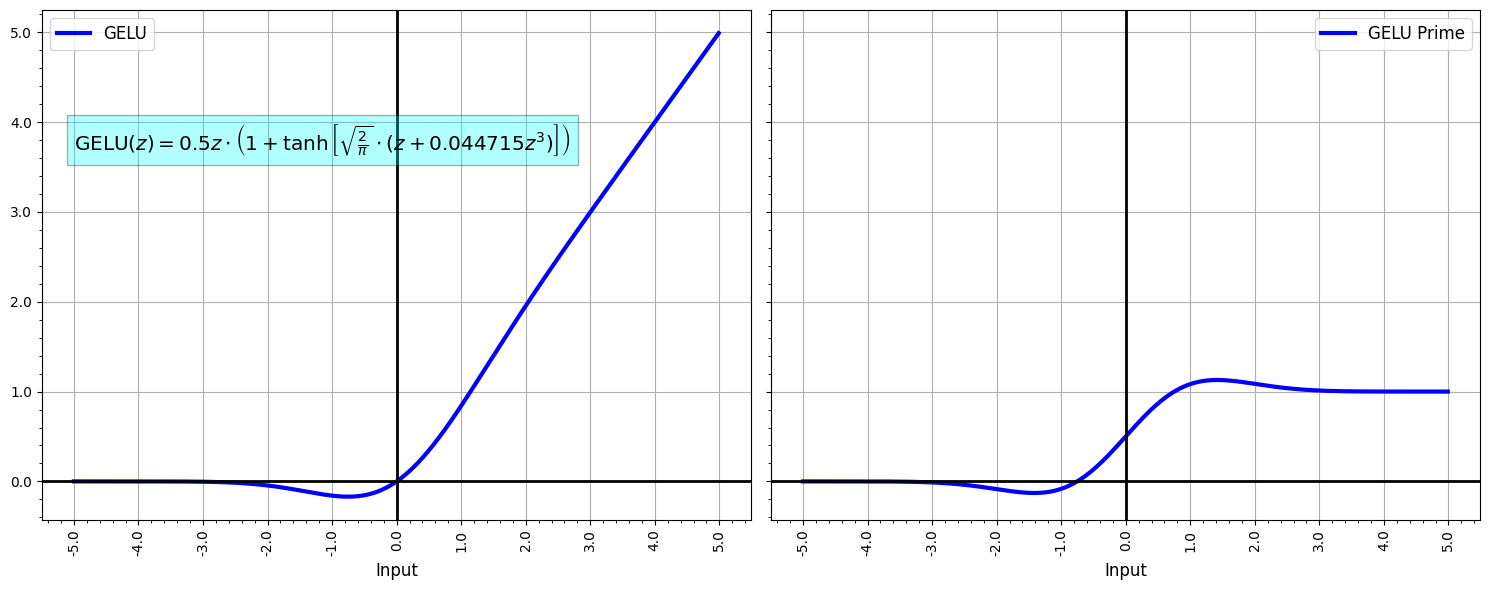

In [20]:
def gelu(z):
    return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3)))

def gelu_prime(z):
    # Approximate derivative
    return 0.5 * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3))) + \
           0.5 * z * (1 - np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3))**2) * \
           np.sqrt(2 / np.pi) * (1 + 3 * 0.044715 * z**2)

col1 = 'GELU'
col2 = 'GELU Prime'

# add two columns in the dataframe for function values and its prime
data_df[col1] = data_df['x'].apply(lambda x: gelu(x))
data_df[col2] = data_df['x'].apply(lambda x: gelu_prime(x))

# create figure and its axis objects
fig, axes = plt.subplots(1, 2, sharey=True)

# Select Major and Minor axis formatings
yMajorLocator = 1.0
yMinorLocator = 0.2
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

# Define the equation
eq1 = r'$\text{GELU}(z) = 0.5z \cdot \left(1 + \tanh\left[\sqrt{\frac{2}{\pi}} \cdot (z + 0.044715z^3)\right]\right)$'
ax = axes[0]
xLoc = -5.0
yLoc = 4.0

fn_plot_equation(ax, xLoc , yLoc, eq1)
plt.tight_layout()
#plt.savefig(os.path.join(outDir, '{}.png'.format(col1.lower())))

### Hot Trends in the market

The general trend has moved beyond searching for a single "best" fixed activation function. Instead, the focus is on:
- **Learnability**: Letting the network discover the activation shape (ACON, PAU).
- **Task-Specificity**: Designing activations for specific domains, like periodic data (Snake) or implicit representations (SIREN).
- **Efficiency and Stability**: Creating simple, bounded, and numerically stable functions for robust training (Seagull, Squareplus).



### Summary:
#### ACON (ActivateOrNot) - Smart activation that learns when to be linear vs non-linear
ACON(z) = $(\beta - \gamma) \cdot z \cdot \sigma(\beta \cdot \gamma \cdot z) + \gamma \cdot z$

For $\beta$ = 1.0 and $\gamma$ = 1.0, it is linear

WHEN TO USE:
- When you want the network to learn whether to use linear or non-linear activation
- Deep networks where different layers may benefit from different activation types
- State-of-the-art computer vision models
- As a replacement for Swish/ReLU in modern architectures


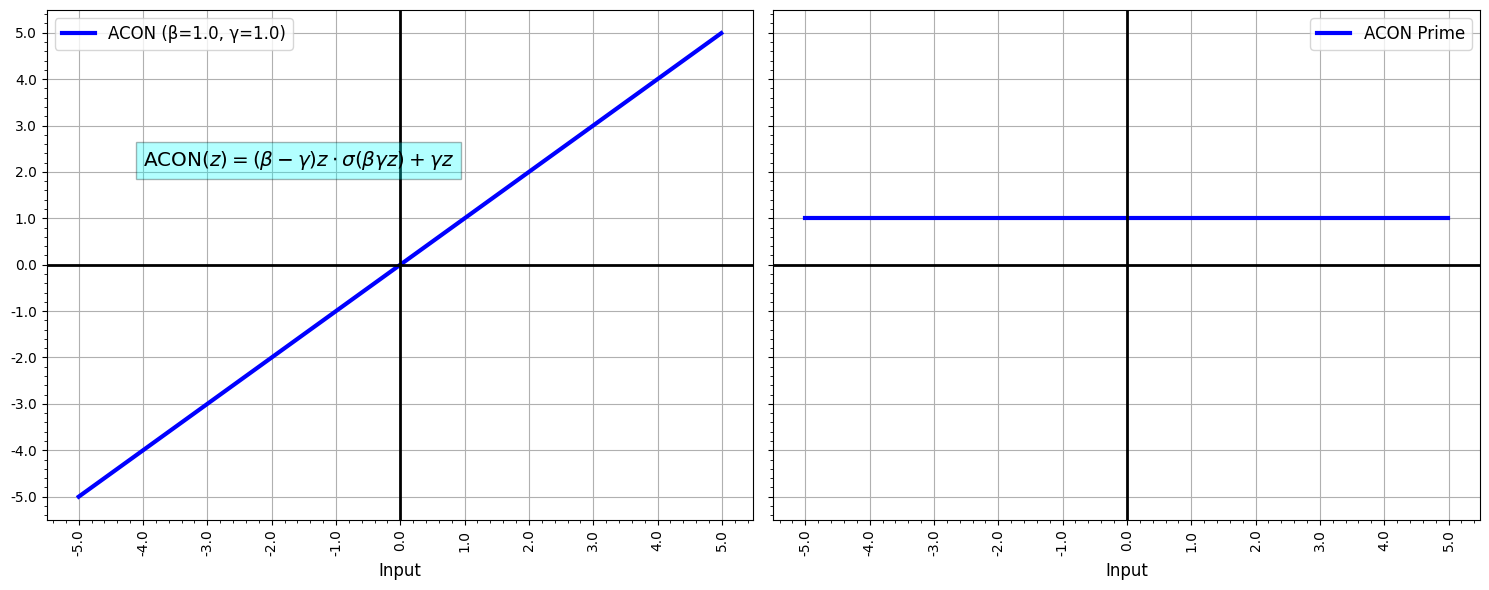

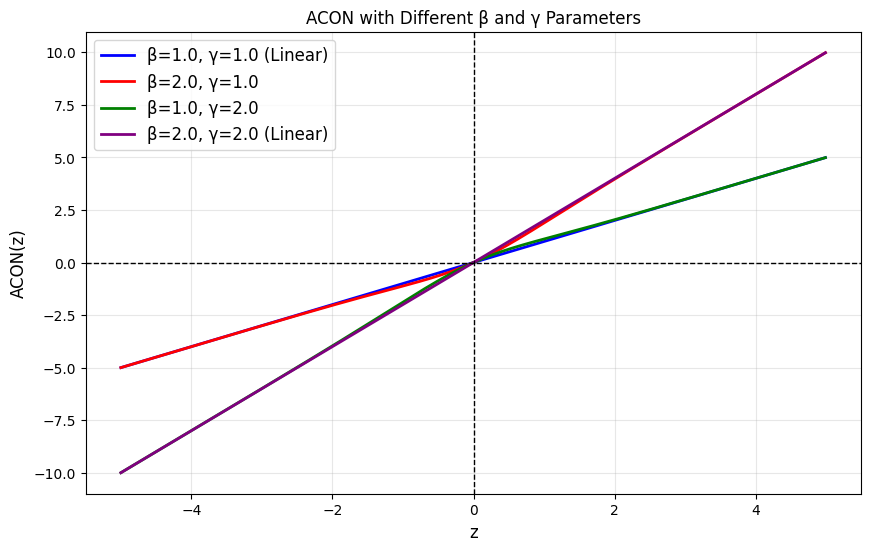

In [21]:
def acon(z, beta=1.0, gamma=1.0):
    """
    ACON activation function.
    
    ACON(z) = (β - γ) * z * σ(β * γ * z) + γ * z
    
    Args:
        z: Input array
        beta: Parameter controlling non-linearity (default=1.0)
        gamma: Parameter controlling linear component (default=1.0)
    
    Returns:
        ACON activation output
    """
    # When beta == gamma, ACON becomes linear
    sig = 1 / (1 + np.exp(-beta * gamma * z))
    return (beta - gamma) * z * sig + gamma * z

def acon_prime(z, beta=1.0, gamma=1.0):
    """
    Derivative of ACON (numerical for stability).
    """
    dz = 1e-6
    dj = acon(z + dz, beta, gamma) - acon(z - dz, beta, gamma)
    return dj / (2 * dz)

# Plotting ACON with different parameter values
col1 = 'ACON (β=1.0, γ=1.0)'
col2 = 'ACON Prime'

data_df[col1] = data_df['x'].apply(lambda x: acon(x, beta=1.0, gamma=1.0))
data_df[col2] = data_df['x'].apply(lambda x: acon_prime(x, beta=1.0, gamma=1.0))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 1.0
yMinorLocator = 0.2
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'$\mathrm{ACON}(z) = (\beta - \gamma)z \cdot \sigma(\beta\gamma z) + \gamma z$'
xLoc = -4
yLoc = 2.5
fn_plot_equation(ax, xLoc, yLoc, eq1)

plt.tight_layout()

# Optional: Show ACON with different β,γ combinations
fig, ax = plt.subplots(figsize=(10, 6))

param_combos = [
    (1.0, 1.0, 'β=1.0, γ=1.0 (Linear)', 'blue'),
    (2.0, 1.0, 'β=2.0, γ=1.0', 'red'),
    (1.0, 2.0, 'β=1.0, γ=2.0', 'green'),
    (2.0, 2.0, 'β=2.0, γ=2.0 (Linear)', 'purple')
]

for beta, gamma, label, color in param_combos:
    y_vals = [acon(x, beta, gamma) for x in x_range]
    ax.plot(x_range, y_vals, color=color, label=label, linewidth=2)

ax.axhline(0, color='k', lw=1, linestyle='--')
ax.axvline(0, color='k', lw=1, linestyle='--')
ax.set_xlabel('z')
ax.set_ylabel('ACON(z)')
ax.set_title('ACON with Different β and γ Parameters')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.show()

#### PAU (Padé Activation Unit, 2020)
Flexible rational function that can approximate many shapes.

Pau = (a + b $\times$ z) / (1 + c $\times$ z + d $\times$ $z^2$)

Where a, b, c, and d  are configurable and default a=1.0, b=1.0, c=1.0, d=1.0

Throw in as many parameters as you want eg. e $\times$ z $\times$ abs(z) 

WHEN TO USE:
- When you need high approximation accuracy for complex functions
- Scientific computing applications
- When you want the network to learn the optimal activation shape
- As a universal approximator for activation functions

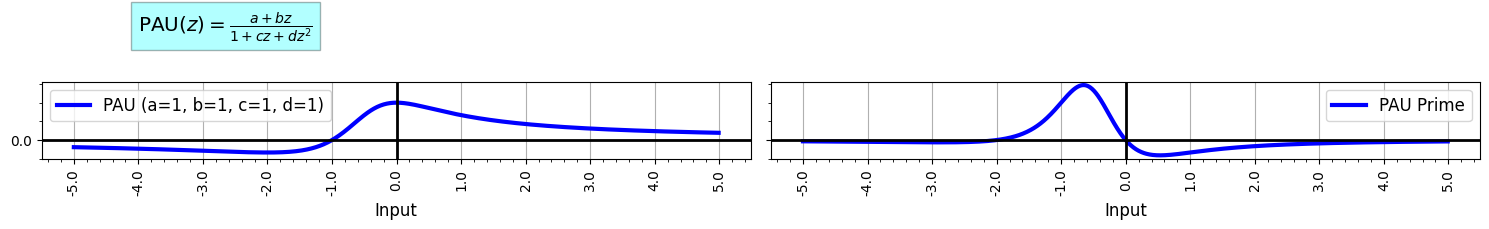

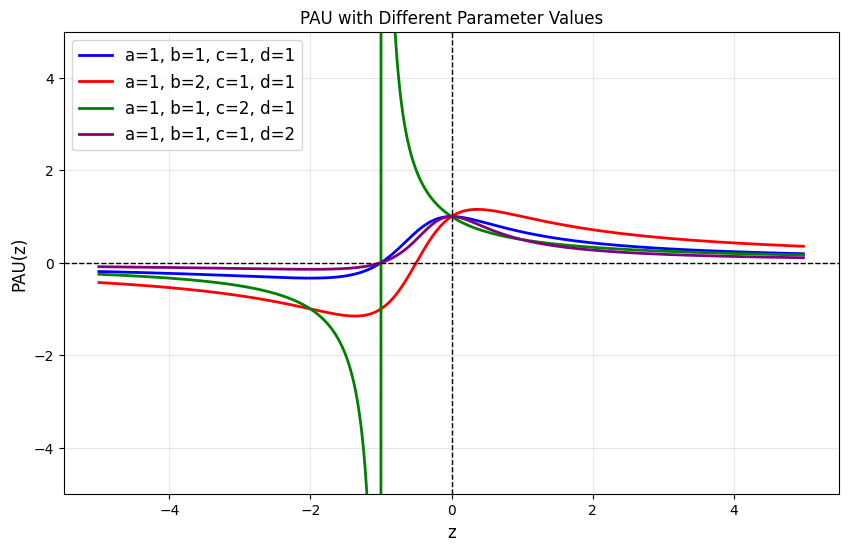

In [22]:
def pau(z, a=1.0, b=1.0, c=1.0, d=1.0):
    """
    Padé Activation Unit.
    
    PAU(z) = (a + b * z) / (1 + c * z + d * z^2)
    
    Args:
        z: Input array
        a, b, c, d: Learnable parameters
    
    Returns:
        Rational function approximation
    """
    eps = 1e-8
    numerator = a + b * z
    denominator = 1 + c * z + d * z**2
    denominator = np.where(np.abs(denominator) < eps, eps, denominator)
    return numerator / denominator

def pau_prime(z, a=1.0, b=1.0, c=1.0, d=1.0):
    """
    Derivative of PAU (numerical for stability).
    """
    dz = 1e-6
    dj = pau(z + dz, a, b, c, d) - pau(z - dz, a, b, c, d)
    return dj / (2 * dz)

# Plotting PAU with different parameter sets
col1 = 'PAU (a=1, b=1, c=1, d=1)'
col2 = 'PAU Prime'

data_df[col1] = data_df['x'].apply(lambda x: pau(x))
data_df[col2] = data_df['x'].apply(lambda x: pau_prime(x))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 2.0
yMinorLocator = 0.5
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'$\mathrm{PAU}(z) = \frac{a + bz}{1 + cz + dz^2}$'
xLoc = -4
yLoc = 3.5
fn_plot_equation(ax, xLoc, yLoc, eq1)

plt.tight_layout()

# Optional: Show PAU with different parameter sets
fig, ax = plt.subplots(figsize=(10, 6))

param_sets = [
    (1.0, 1.0, 1.0, 1.0, 'a=1, b=1, c=1, d=1', 'blue'),
    (1.0, 2.0, 1.0, 1.0, 'a=1, b=2, c=1, d=1', 'red'),
    (1.0, 1.0, 2.0, 1.0, 'a=1, b=1, c=2, d=1', 'green'),
    (1.0, 1.0, 1.0, 2.0, 'a=1, b=1, c=1, d=2', 'purple'),
]

for a, b, c, d, label, color in param_sets:
    y_vals = [pau(x, a, b, c, d) for x in x_range]
    ax.plot(x_range, y_vals, color=color, label=label, linewidth=2)

ax.axhline(0, color='k', lw=1, linestyle='--')
ax.axvline(0, color='k', lw=1, linestyle='--')
ax.set_xlabel('z')
ax.set_ylabel('PAU(z)')
ax.set_title('PAU with Different Parameter Values')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_ylim(-5, 5)
plt.show()

#### SIREN: Sine wave activation for high-frequency signal representation
Quick 30 cycles of sine wave ($\theta_0$ = 30.0)

$
\begin{align}
SIREN(z) &= sin(\theta_0 \times z)
\end{align}
$

WHEN TO USE:
- Implicit neural representations (3D scenes, images, audio)
- Solving differential equations
- Signal processing applications
- Computer graphics and neural rendering
- When you need smooth derivatives and high-frequency details

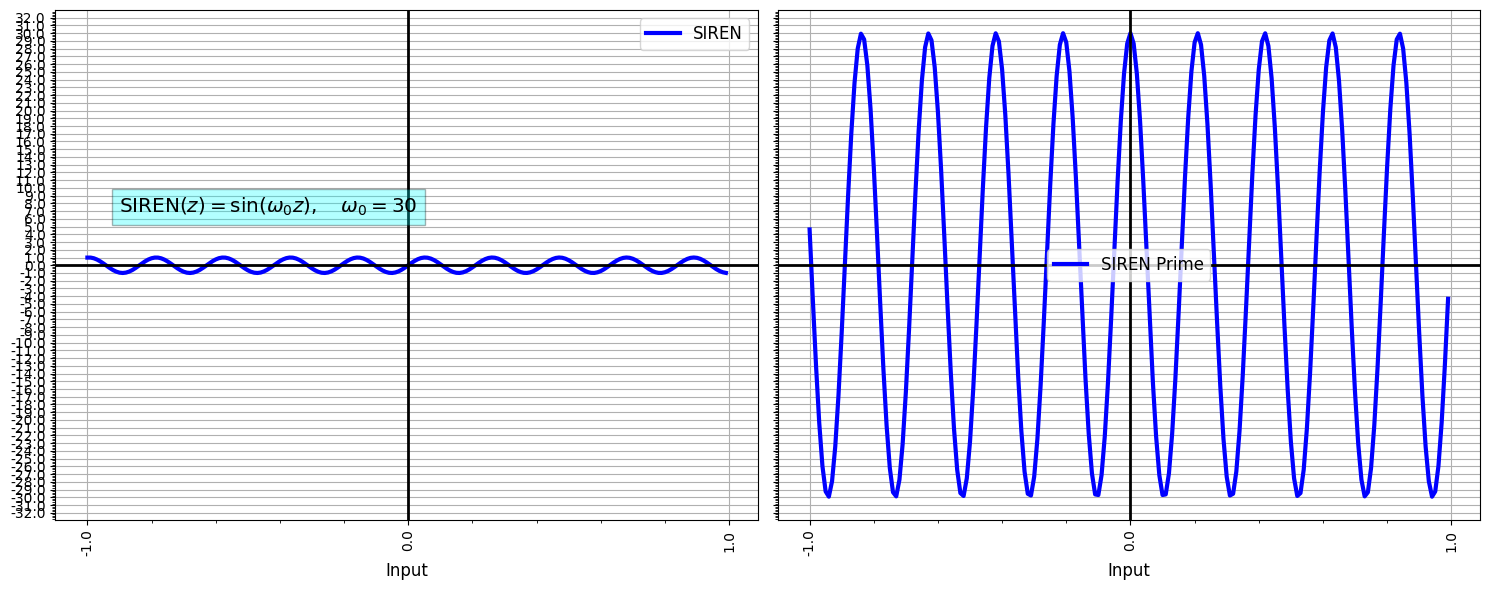

In [23]:
def siren(z, omega0=30.0):
    """
    SIREN activation function - sine wave.
    
    Args:
        z: Input array
        omega0: Frequency parameter (default=30.0)
    
    Returns:
        Sine of omega0 * z
    """
    return np.sin(omega0 * z)

def siren_prime(z, omega0=30.0):
    """
    Derivative of SIREN.
    """
    return omega0 * np.cos(omega0 * z)

# Plotting
col1 = 'SIREN'
col2 = 'SIREN Prime'

# Use smaller range for SIREN
x_range_siren = np.arange(-1, 1, 0.01)
data_df_siren = pd.DataFrame(x_range_siren, columns=['x'])

data_df_siren[col1] = data_df_siren['x'].apply(lambda x: siren(x))
data_df_siren[col2] = data_df_siren['x'].apply(lambda x: siren_prime(x))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 1.0
yMinorLocator = 0.2
fn_plot_activation(axes, data_df_siren, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'$\mathrm{SIREN}(z) = \sin(\omega_0 z), \quad \omega_0 = 30$'
xLoc = -0.9
yLoc = 9
fn_plot_equation(ax, xLoc, yLoc, eq1)

plt.tight_layout()

#### FReLU(Funnel Activation, 2021)
ReLU with spatial context awareness for vision tasks. This uses a depthwise convolution for spatial context and learns a thereshold.

FReLU = max (z x threshold)

WHEN TO USE:
- Computer vision tasks, especially semantic segmentation
- When spatial context is important
- Replacing ReLU in convolutional networks
- Tasks requiring pixel-level understanding

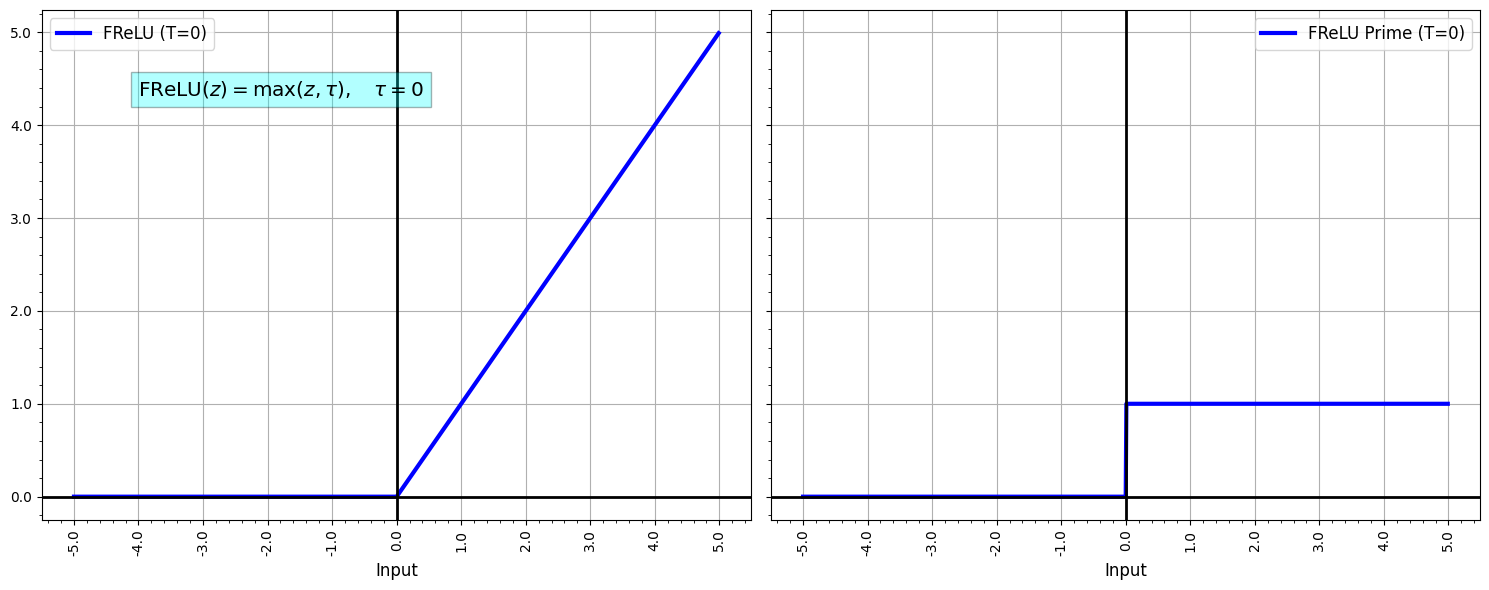

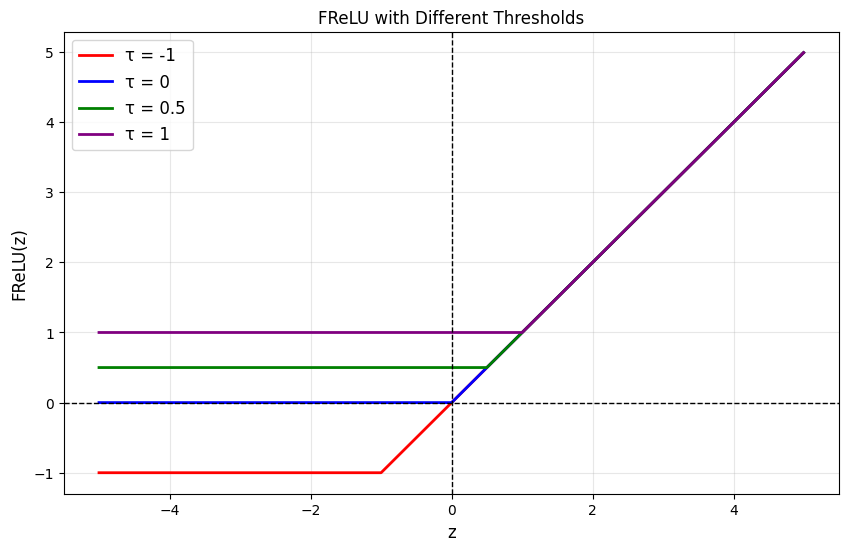

In [24]:
def freLU(z, threshold=0.0):
    """
    FReLU activation function (simplified version).
    
    For demonstration without convolution, this is a parametric ReLU.
    Full FReLU uses depthwise convolution for spatial context.
    
    Args:
        z: Input array
        threshold: Learnable threshold (default=0.0 for standard ReLU)
    
    Returns:
        max(z, threshold)
    """
    return np.maximum(z, threshold)

def freLU_prime(z, threshold=0.0):
    """
    Derivative of simplified FReLU.
    """
    return np.where(z > threshold, 1, 0)

# Plotting with different thresholds
col1 = 'FReLU (T=0)'
col2 = 'FReLU Prime (T=0)'

data_df[col1] = data_df['x'].apply(lambda x: freLU(x, threshold=0))
data_df[col2] = data_df['x'].apply(lambda x: freLU_prime(x, threshold=0))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 1.0
yMinorLocator = 0.2
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'$\mathrm{FReLU}(z) = \max(z, \tau), \quad \tau = 0$'
xLoc = -4
yLoc = 4.5
fn_plot_equation(ax, xLoc, yLoc, eq1)

plt.tight_layout()

# Optional: Show FReLU with different thresholds
fig, ax = plt.subplots(figsize=(10, 6))

thresholds = [-1, 0, 0.5, 1]
colors = ['red', 'blue', 'green', 'purple']

for t, c in zip(thresholds, colors):
    y_vals = [freLU(x, threshold=t) for x in x_range]
    ax.plot(x_range, y_vals, color=c, label=f'τ = {t}', linewidth=2)

ax.axhline(0, color='k', lw=1, linestyle='--')
ax.axvline(0, color='k', lw=1, linestyle='--')
ax.set_xlabel('z')
ax.set_ylabel('FReLU(z)')
ax.set_title('FReLU with Different Thresholds')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

#### Squareplus
Stable, smooth alternative to Softplus for positive outputs

$
\begin{aligned}
SquarePlus = 0.5 * (z + \sqrt{(z^2 + b)})
\end{aligned}
$

WHEN TO USE:
- When you need a smooth, always-positive activation
- Probabilistic models and Bayesian neural networks
- As a numerically stable alternative to Softplus
- When you want bounded derivatives for stable training
- Regression tasks with positive outputs



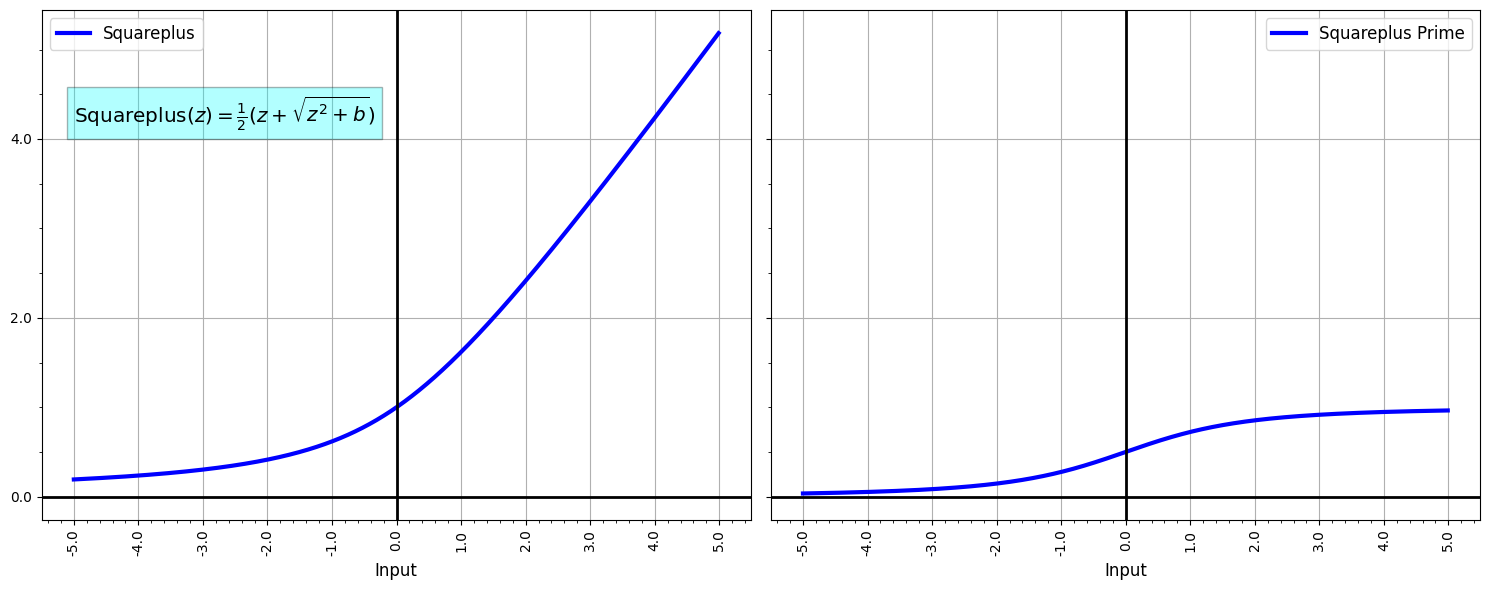

In [25]:
def squareplus(z, b=4):
    """
    Squareplus activation function.
    
    Args:
        z: Input array
        b: Smoothness parameter (default=4)
    
    Returns:
        Smooth, always-positive output
    """
    return 0.5 * (z + np.sqrt(z**2 + b))

def squareplus_prime(z, b=4):
    """
    Derivative of Squareplus.
    """
    return 0.5 * (1 + z / np.sqrt(z**2 + b))

# Plotting
col1 = 'Squareplus'
col2 = 'Squareplus Prime'

data_df[col1] = data_df['x'].apply(lambda x: squareplus(x))
data_df[col2] = data_df['x'].apply(lambda x: squareplus_prime(x))

fig, axes = plt.subplots(1, 2, sharey=True)

yMajorLocator = 2.0
yMinorLocator = 0.5
fn_plot_activation(axes, data_df, col1, col2, yMajorLocator, yMinorLocator)

ax = axes[0]
eq1 = r'$\mathrm{Squareplus}(z) = \frac{1}{2}(z + \sqrt{z^2 + b})$'
xLoc = -5
yLoc = 4.5
fn_plot_equation(ax, xLoc, yLoc, eq1)

plt.tight_layout()


These represent the cutting edge of activation function research, each with specific strengths for different applications!

For most practitioners today, GELU is the standard in Transformers, Mish is a strong performer in CNNs, and ReLU/its variants remain popular for their simplicity. However, if you are working on a novel architecture or a specific problem, exploring newer adaptive functions like ACON or domain-specific ones like SIREN could be highly beneficial.